In [10]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import numpy as np
from nem_battery.load import PROJECT_ROOT
from nem_battery.features import split_by_time, FEATURES, TARGET
from nem_battery.battery import BatterySpec, optimise_day, realised_profit
from scipy.optimize import linprog

model_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "features_sa1_30min.parquet")
train, valid, test = split_by_time(model_df)
valid = valid.copy()

params = dict(n_estimators=500, learning_rate=0.05, num_leaves=31,
              min_child_samples=50, random_state=42, verbose=-1)
lgbm = lgb.LGBMRegressor(objective="l1", **params).fit(train[FEATURES], train[TARGET])
valid["forecast"] = lgbm.predict(valid[FEATURES])

# Typical-day profile: median price per half-hour, from TRAIN only
typical = train.groupby("slot")[TARGET].median()
valid["typical"] = valid["slot"].map(typical)
spec = BatterySpec()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
day = valid[valid["date"] == "2025-03-12"].sort_values("slot")
actual = day[TARGET].to_numpy()

plans = {
    "typical day": optimise_day(day["typical"], spec),
    "forecast (LightGBM)": optimise_day(day["forecast"], spec),
    "perfect foresight": optimise_day(actual, spec),
}
for name, sched in plans.items():
    print(f"{name:22s} profit: ${realised_profit(sched, actual, spec):8.2f}")

typical day            profit: $  213.41
forecast (LightGBM)    profit: $  199.53
perfect foresight      profit: $  304.33


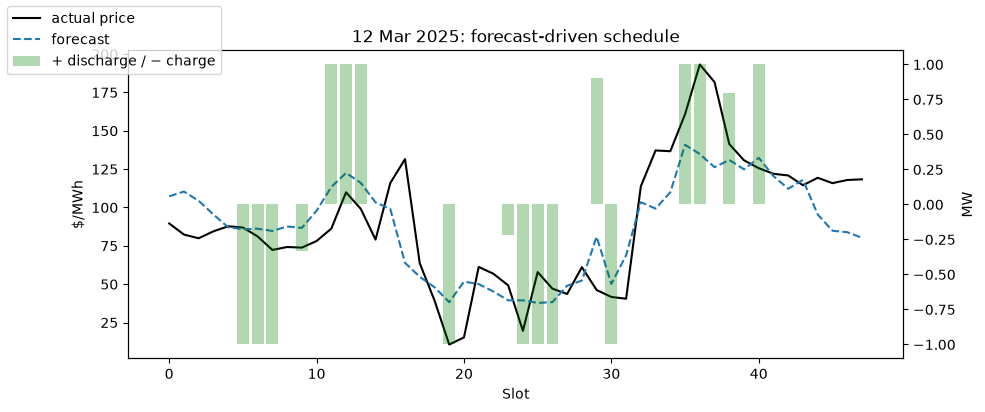

In [9]:
sched = plans["forecast (LightGBM)"]
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(day["slot"], actual, label="actual price", color="black")
ax1.plot(day["slot"], day["forecast"], label="forecast", linestyle="--")
ax1.set_ylabel("$/MWh")
ax2 = ax1.twinx()
ax2.bar(day["slot"], sched["discharge_mw"] - sched["charge_mw"], alpha=0.3, color="green",
        label="+ discharge / − charge")
ax2.set_ylabel("MW")
ax1.set_xlabel("Slot")
ax1.set_title("12 Mar 2025: forecast-driven schedule")
fig.legend(loc="upper left")
plt.show()

The forecast underestimated the evening peak by about $50, yet the battery still discharged at the right time. Morning circle is risky when it peaks at slot 12m but it actually came at slot 16. The battery sold too early, at abt $85-100 instead of $130. With 90% efficiency and $10 degradation, buying at ~$85 needs a sale above about $105 just to break even. Small margins plus forecast timing errors mean this cycle may lose money.

In [11]:
# full year battery simulation
def simulate(df: pd.DataFrame, plan_col: str | None, plan_spec: BatterySpec, pay_spec: BatterySpec) -> pd.DataFrame:
    """Plan each day with `plan_col` prices (None = actual prices = perfect foresight),
    then pay the schedule at ACTUAL prices."""
    rows = []
    for date, day in df.groupby("date"):
        day = day.sort_values("slot")
        actual = day[TARGET].to_numpy()
        plan_prices = actual if plan_col is None else day[plan_col].to_numpy()
        sched = optimise_day(plan_prices, plan_spec)
        rows.append({
            "date": date,
            "profit": realised_profit(sched, actual, pay_spec),
            "mwh_out": sched["discharge_mw"].sum() * pay_spec.dt_h,
        })
    return pd.DataFrame(rows)

In [12]:
runs = {
    "typical day": simulate(valid, "typical", spec, spec),
    "forecast (LightGBM)": simulate(valid, "forecast", spec, spec),
    "perfect foresight": simulate(valid, None, spec, spec),
}

In [13]:
perfect_total = runs["perfect foresight"]["profit"].sum()

summary = pd.DataFrame({
    name: {
        "total profit ($)": r["profit"].sum(),
        "capture rate (%)": 100 * r["profit"].sum() / perfect_total,
        "mean daily ($)": r["profit"].mean(),
        "std daily ($)": r["profit"].std(),
        "worst day ($)": r["profit"].min(),
        "5th pct day ($)": r["profit"].quantile(0.05),
        "losing days (%)": 100 * (r["profit"] < 0).mean(),
        "cycles per day": r["mwh_out"].mean() / spec.energy_mwh,
    }
    for name, r in runs.items()
}).T.round(1)

summary.loc["no trade"] = 0
summary

,total profit ($),capture rate (%),mean daily ($),std daily ($),worst day ($),5th pct day ($),losing days (%),cycles per day
typical day,160085.4,55.7,438.6,1510.1,-704.1,-9.1,5.8,1.7
forecast (LightGBM),158795.4,55.3,435.1,1295.8,-324.1,9.8,4.7,1.7
perfect foresight,287328.4,100.0,787.2,2132.2,17.8,196.2,0.0,2.2
no trade,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


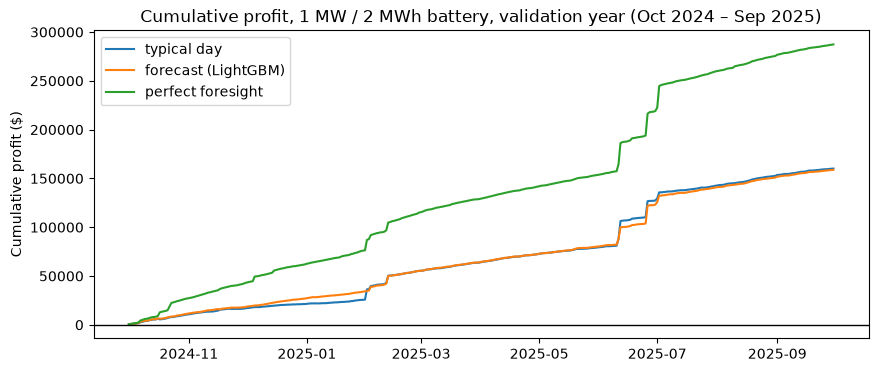

In [ ]:
# cumulative profit plot
fig, ax = plt.subplots(figsize=(10, 4))
for name, r in runs.items():
    ax.plot(r["date"], r["profit"].cumsum(), label=name)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Cumulative profit, 1 MW / 2 MWh battery, validation year (Oct 2024 – Sep 2025)")
ax.set_ylabel("Cumulative profit ($)")
ax.legend()
plt.show()

In [15]:
for hurdle in [20, 40, 60]:
    plan_spec = BatterySpec(degradation_cost=hurdle)
    r = simulate(valid, "forecast", plan_spec, spec)
    print(f"hurdle ${hurdle}: total ${r['profit'].sum():,.0f}  "
          f"capture {100 * r['profit'].sum() / perfect_total:.1f}%  "
          f"cycles/day {r['mwh_out'].mean() / spec.energy_mwh:.2f}")

hurdle $20: total $159,662  capture 55.6%  cycles/day 1.44
hurdle $40: total $156,245  capture 54.4%  cycles/day 1.19
hurdle $60: total $152,007  capture 52.9%  cycles/day 1.05


In [16]:
# spike model 
SPIKE = 300
y_train = (train[TARGET] > SPIKE).astype(int)

clf = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31,
                         min_child_samples=50, random_state=42, verbose=-1)
clf.fit(train[FEATURES], y_train)
valid["p_spike"] = clf.predict_proba(valid[FEATURES])[:, 1]

# What's a "typical" spike price? (from TRAIN only)
spike_prices = train.loc[train[TARGET] > SPIKE, TARGET]
print(f"Spike prices in train: mean ${spike_prices.mean():,.0f}, median ${spike_prices.median():,.0f}")
spike_value = spike_prices.median()

Spike prices in train: mean $695, median $375


In [ ]:
# spike aware planning prices
# alpha = 0.5 means overestimate high risk by about 2x.a = 0.5 half influence, a = 1 trust fully
for alpha in [0.5, 1.0]:
    col = f"risk_{alpha}"
    valid[col] = valid["forecast"] + alpha * valid["p_spike"] * (spike_value - valid["forecast"]).clip(lower=0)
    runs[f"spike-aware (α={alpha})"] = simulate(valid, col, spec, spec)
    print(col, f"total ${runs[f'spike-aware (α={alpha})']['profit'].sum():,.0f}")

risk_0.5 total $160,378
risk_1.0 total $158,963


In [18]:
# compare models 
spike_days = ["2025-02-01", "2025-02-12", "2025-06-12", "2025-06-26", "2025-07-02"]
compare = pd.DataFrame({
    name: r.set_index("date").loc[pd.to_datetime(spike_days), "profit"]
    for name, r in runs.items()
}).round(0)
compare

,typical day,forecast (LightGBM),perfect foresight,spike-aware (α=0.5),spike-aware (α=1.0)
date,,,,,
2025-02-01,10553.0,579.0,10676.0,591.0,588.0
2025-02-12,7471.0,7795.0,7948.0,7793.0,7790.0
2025-06-12,18212.0,12176.0,21578.0,12864.0,12873.0
2025-06-26,16248.0,18204.0,22337.0,18107.0,18101.0
2025-07-02,6182.0,6703.0,21977.0,5923.0,3773.0


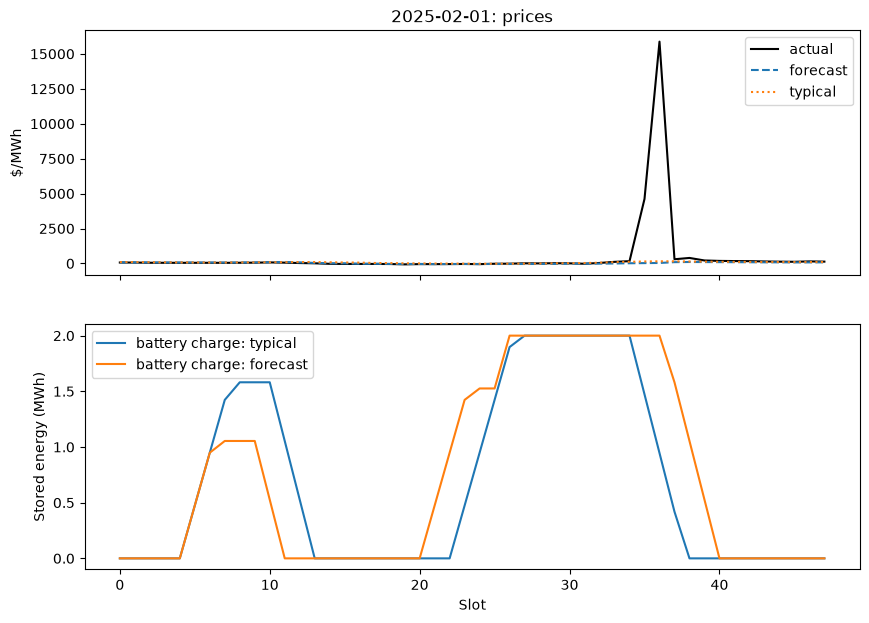

In [19]:
d = "2025-02-01"
day = valid[valid["date"] == d].sort_values("slot")
actual = day[TARGET].to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(day["slot"], actual, label="actual", color="black")
axes[0].plot(day["slot"], day["forecast"], "--", label="forecast")
axes[0].plot(day["slot"], day["typical"], ":", label="typical")
axes[0].set_ylabel("$/MWh"); axes[0].legend(); axes[0].set_title(f"{d}: prices")

for name, col in [("typical", "typical"), ("forecast", "forecast")]:
    s = optimise_day(day[col], spec)
    axes[1].plot(day["slot"], s["soc_mwh"], label=f"battery charge: {name}")
axes[1].set_ylabel("Stored energy (MWh)"); axes[1].set_xlabel("Slot"); axes[1].legend()
plt.show()